# 04 — Advanced Modeling, Optimasi & Submission

**Tujuan.** Meningkatkan macro F1 baseline dengan tiga perubahan yang semuanya bebas
leakage:

1. **Target encoding out-of-fold** untuk `courier_id`, `hub_id`, `customer_id`
   (5-fold, smoothing `prior × 50`) → menggantikan ID kategorikal kardinalitas tinggi.
2. **Bobot kelas** berbanding terbalik dengan frekuensi → kelas minoritas tidak diabaikan.
3. **Tuning pengali probabilitas per kelas** (coordinate ascent pada data validasi) →
   `argmax` disesuaikan agar macro F1 maksimal.

Artefak akhir: `submissions/submission.csv`, `data/processed/lgbm_final.txt`,
`data/processed/preprocess.pkl` (untuk inferensi tanpa retraining).

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
%matplotlib inline

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 100)

# root proyek = folder terdekat ke atas yang berisi src/ dan data/
BASE = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src").is_dir() and (p / "data").is_dir())
sys.path.insert(0, str(BASE))

import time, json
import lightgbm as lgb
from sklearn.metrics import (f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, log_loss,
                             precision_score, recall_score)

from src.data_loader import PROCESSED_DIR, SUBMISSION_DIR, TARGET, CLASSES
from src.features import TE_COLS, add_te_columns
from src.models import (PARAMS, N_ROUNDS, HOLD_OUT, load_matrices, split_indices,
                        class_weights, train_model, tune_multipliers,
                        save_bundle, predict_from_bundle)
from src.utils import set_seed, evaluate, print_report, save_json

set_seed()
K = len(CLASSES)

In [2]:
d = load_matrices()
tr, te, y = d["tr"], d["te"], d["y"]
raw_id_tr, raw_id_te = d["raw_id_tr"], d["raw_id_te"]

idx_tr, idx_va = split_indices(y, HOLD_OUT)
y_tr, y_va = y[idx_tr], y[idx_va]
tr_part = tr.iloc[idx_tr].reset_index(drop=True)
va_part = tr.iloc[idx_va].reset_index(drop=True)
del tr
d.pop("tr", None)          
print(f"train {tr_part.shape} | valid {va_part.shape}")

# ---- target encoding out-of-fold (train) & tabel penuh (valid/test) ----
te_maps = add_te_columns(tr_part, va_part, te,
                         {c: raw_id_tr[c][idx_tr] for c in TE_COLS},
                         {c: raw_id_tr[c][idx_va] for c in TE_COLS},
                         {c: raw_id_te[c] for c in TE_COLS},
                         y_tr)

# ID mentah sudah diwakili target encoding -> dibuang dari fitur
for c in TE_COLS:
    for df_ in (tr_part, va_part, te):
        if c in df_.columns:
            df_.drop(columns=[c], inplace=True)

del raw_id_tr             
d.pop("raw_id_te", None)
raw_id_te = None
FEATS = list(tr_part.columns)
CAT_USE = [c for c in d["cat_cols"] if c in FEATS]
print(f"{len(FEATS)} fitur dipakai ({len(CAT_USE)} kategorikal)")

  dimuat: train (1243617, 199) | test (362245, 198)  [122.6s]
17 kolom kategorikal, 105 kolom numerik
train (1094382, 122) | valid (149235, 122)
  target encoding selesai: courier_id (23,806 nilai unik)
  target encoding selesai: hub_id (654 nilai unik)
  target encoding selesai: customer_id (538,977 nilai unik)
140 fitur dipakai (14 kategorikal)


In [3]:
w_class = class_weights(y_tr, K)
print("bobot kelas:", {c: round(float(w), 3) for c, w in zip(CLASSES, w_class)})

model = train_model(tr_part, va_part, y_tr, y_va, FEATS, CAT_USE,
                    params=PARAMS, n_rounds=N_ROUNDS, weights=w_class,
                    early_stopping=40)
model.save_model(str(PROCESSED_DIR / "lgbm_final.txt"))
print("model disimpan:", PROCESSED_DIR / "lgbm_final.txt")

n_train_rows, n_valid_rows = len(tr_part), len(va_part)
del tr_part               

bobot kelas: {'normal': 0.375, 'konfirmasi_alamat': 0.651, 'tertunda_operasional': 0.958, 'gagal_antar_awal': 1.429, 'retur_pengirim': 2.025, 'rusak_perjalanan': 2.868, 'klaim_hilang': 4.718}
Training until validation scores don't improve for 40 rounds
[50]	valid_0's multi_logloss: 1.11569
[100]	valid_0's multi_logloss: 1.10561
Early stopping, best iteration is:
[95]	valid_0's multi_logloss: 1.10548
  selesai: 95 iterasi terbaik  [839.4s]
model disimpan: C:\Datavidia\TASK-1\data\processed\lgbm_final.txt


In [4]:
p_va = model.predict(va_part[FEATS], num_iteration=model.best_iteration)
pred_va = p_va.argmax(1)
f1_macro = f1_score(y_va, pred_va, average="macro")

print("ADVANCED (target encoding + bobot kelas)")
for k, v in evaluate(y_va, pred_va, p_va).items():
    print(f"  {k:12s}: {v}")
print()
print_report(y_va, pred_va, CLASSES)

ADVANCED (target encoding + bobot kelas)
  macro_f1    : 0.54923
  weighted_f1 : 0.6451
  accuracy    : 0.62983
  log_loss    : 1.02993

                      precision    recall  f1-score   support

              normal     0.8553    0.6630    0.7470     56824
   konfirmasi_alamat     0.7132    0.6253    0.6663     32749
tertunda_operasional     0.6903    0.7420    0.7152     22260
    gagal_antar_awal     0.3895    0.4339    0.4105     14921
      retur_pengirim     0.4166    0.5455    0.4724     10529
    rusak_perjalanan     0.3333    0.5606    0.4180      7433
        klaim_hilang     0.3050    0.6499    0.4152      4519

            accuracy                         0.6298    149235
           macro avg     0.5290    0.6029    0.5492    149235
        weighted avg     0.6793    0.6298    0.6451    149235



,kelas,n_valid,precision,recall,f1
0,normal,56824,0.8553,0.6630,0.7470
1,konfirmasi_alamat,32749,0.7132,0.6253,0.6663
2,tertunda_operasional,22260,0.6903,0.7420,0.7152
3,gagal_antar_awal,14921,0.3895,0.4339,0.4105
4,retur_pengirim,10529,0.4166,0.5455,0.4724
5,rusak_perjalanan,7433,0.3333,0.5606,0.4180
6,klaim_hilang,4519,0.3050,0.6499,0.4152


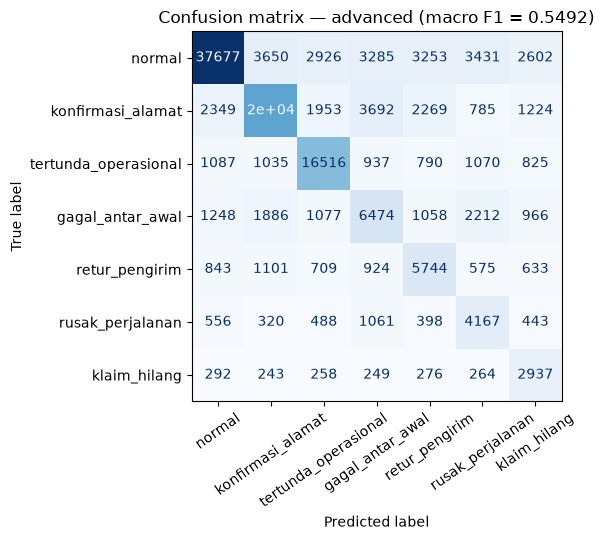

,fitur,gain,gain_pct
36,co_hub,1.119893e+06,10.25
35,cus_complaint,8.873711e+05,8.12
34,cus_addr_q,8.606968e+05,7.88
121,te_courier_id_2,7.047597e+05,6.45
95,first_hub,6.560881e+05,6.01
4,declared_value,6.489908e+05,5.94
122,te_courier_id_3,5.242579e+05,4.80
119,te_courier_id_0,4.494044e+05,4.11
137,te_customer_id_4,4.398960e+05,4.03
96,last_hub,4.268169e+05,3.91


In [5]:
per_class = pd.DataFrame({
    "kelas": CLASSES,
    "n_valid": np.bincount(y_va, minlength=K),
    "precision": precision_score(y_va, pred_va, average=None, labels=range(K), zero_division=0),
    "recall": recall_score(y_va, pred_va, average=None, labels=range(K), zero_division=0),
    "f1": f1_score(y_va, pred_va, average=None, labels=range(K), zero_division=0),
})
display(per_class.round(4))

fig, ax = plt.subplots(figsize=(7, 5.5))
ConfusionMatrixDisplay.from_predictions(y_va, pred_va, display_labels=CLASSES,
                                        xticks_rotation=35, ax=ax, colorbar=False,
                                        cmap="Blues")
ax.set_title(f"Confusion matrix — advanced (macro F1 = {f1_macro:.4f})")
plt.tight_layout(); plt.show()

imp = (pd.DataFrame({"fitur": model.feature_name(),
                     "gain": model.feature_importance("gain")})
       .sort_values("gain", ascending=False))
imp["gain_pct"] = (imp["gain"] / imp["gain"].sum() * 100).round(2)
display(imp.head(20))

## Optimasi keputusan: pengali probabilitas per kelas

`argmax` memaksimalkan akurasi, bukan macro F1. Pada data tidak seimbang, probabilitas
kelas minoritas perlu dinaikkan agar recall-nya naik tanpa mengorbankan terlalu banyak
presisi. Pengali dicari dengan coordinate ascent pada data validasi (bukan test) sehingga
tetap valid.

In [6]:
print("macro F1 sebelum tuning :", round(f1_macro, 4))
w_opt, f1_opt = tune_multipliers(p_va, y_va, n_class=K)
print("\npengali optimal :", dict(zip(CLASSES, np.round(w_opt, 3))))
print("macro F1 sesudah tuning :", round(f1_opt, 4))

pred_tuned = (p_va * w_opt).argmax(1)
print()
print_report(y_va, pred_tuned, CLASSES)

macro F1 sebelum tuning : 0.5492
  iterasi 1: macro F1 = 0.5735
  iterasi 2: macro F1 = 0.5751
  iterasi 3: macro F1 = 0.5751
  iterasi 4: macro F1 = 0.5751

pengali optimal : {'normal': np.float32(2.7), 'konfirmasi_alamat': np.float32(2.0), 'tertunda_operasional': np.float32(1.2), 'gagal_antar_awal': np.float32(1.5), 'retur_pengirim': np.float32(1.0), 'rusak_perjalanan': np.float32(1.0), 'klaim_hilang': np.float32(0.5)}
macro F1 sesudah tuning : 0.5751

                      precision    recall  f1-score   support

              normal     0.7965    0.7887    0.7926     56824
   konfirmasi_alamat     0.6919    0.6822    0.6870     32749
tertunda_operasional     0.7335    0.7141    0.7237     22260
    gagal_antar_awal     0.4091    0.4544    0.4306     14921
      retur_pengirim     0.5099    0.4571    0.4820     10529
    rusak_perjalanan     0.4050    0.4760    0.4376      7433
        klaim_hilang     0.4869    0.4590    0.4725      4519

            accuracy                       

## Prediksi data test & pembuatan submission

In [7]:
t0 = time.time()
p_test = model.predict(te[FEATS], num_iteration=model.best_iteration)
print(f"prediksi {len(p_test):,} baris dalam {time.time() - t0:.0f} detik")

pred_test = (p_test * w_opt).argmax(1)
submission = pd.DataFrame({
    "shipment_id": d["test_ids"],
    "status_penanganan": [CLASSES[i] for i in pred_test],
})
display(submission.head())
print(submission.status_penanganan.value_counts(normalize=True).round(4))

prediksi 362,245 baris dalam 64 detik


,shipment_id,status_penanganan
0,SHP-5A64RENJ,normal
1,SHP-BUZSJTV9,konfirmasi_alamat
2,SHP-EGUZBJHQ,normal
3,SHP-YWBRSQLZ,konfirmasi_alamat
4,SHP-JS89CKME,tertunda_operasional


status_penanganan
normal                  0.3723
konfirmasi_alamat       0.2155
tertunda_operasional    0.1479
gagal_antar_awal        0.1123
retur_pengirim          0.0638
rusak_perjalanan        0.0596
klaim_hilang            0.0286
Name: proportion, dtype: float64


In [8]:
# ---- validasi submission terhadap sample_submission.csv ----
from src.data_loader import SAMPLE_SUBMISSION

sample = pd.read_csv(SAMPLE_SUBMISSION)
assert list(submission.columns) == list(sample.columns), "urutan kolom harus sama"
assert len(submission) == len(sample), f"jumlah baris {len(submission)} != {len(sample)}"
assert submission.shipment_id.is_unique, "shipment_id duplikat"
assert set(submission.shipment_id) == set(sample.shipment_id), "id tidak sama dengan sample"
assert submission.status_penanganan.isin(CLASSES).all(), "label di luar 7 kelas resmi"
assert submission.status_penanganan.notna().all(), "ada label kosong"

submission = sample[["shipment_id"]].merge(submission, on="shipment_id", how="left")
assert submission.status_penanganan.notna().all()

out_path = SUBMISSION_DIR / "submission.csv"
submission.to_csv(out_path, index=False)
print("submission disimpan:", out_path)
print("baris:", len(submission))
print(submission.head(10).to_string(index=False))

submission disimpan: C:\Datavidia\TASK-1\submissions\submission.csv
baris: 362245
 shipment_id    status_penanganan
SHP-5A64RENJ               normal
SHP-BUZSJTV9    konfirmasi_alamat
SHP-EGUZBJHQ               normal
SHP-YWBRSQLZ    konfirmasi_alamat
SHP-JS89CKME tertunda_operasional
SHP-9LNYLZ86     rusak_perjalanan
SHP-PWY4696Z               normal
SHP-WAUJB829     rusak_perjalanan
SHP-BN6VRM5F               normal
SHP-DY9R7E6R               normal


## Menyimpan artefak & inferensi tanpa retraining

`preprocess.pkl` menyimpan seluruh kamus transformasi (kategori, tabel target encoding,
prior, pengali kelas, daftar fitur, `best_iteration`). Dengan berkas ini + `lgbm_final.txt`,
prediksi dapat diulang dari CSV mentah tanpa melatih ulang model.

In [9]:
art = save_bundle(model, FEATS, CAT_USE, d["cat_categories"], te_maps, w_opt, y_tr,
                  out_dir=PROCESSED_DIR, name="lgbm_final")

meta = {
    "metric": "macro_f1",
    "valid_macro_f1_argmax": round(float(f1_macro), 5),
    "valid_macro_f1_tuned": round(float(f1_opt), 5),
    "valid_accuracy_tuned": round(float((pred_tuned == y_va).mean()), 5),
    "best_iteration": int(model.best_iteration),
    "n_features": len(FEATS),
    "n_train": int(n_train_rows),
    "n_valid": int(n_valid_rows),
    "params": {k: (float(v) if isinstance(v, (np.floating, float)) else v)
               for k, v in PARAMS.items()},
    "versions": {"lightgbm": lgb.__version__, "pandas": pd.__version__,
                 "polars": pl.__version__, "numpy": np.__version__},
}
import lightgbm as lgb
save_json(meta, PROCESSED_DIR / "meta.json")
print(json.dumps(meta, indent=2)[:600])
print("\nberkas di data/processed:",
      sorted(p.name for p in PROCESSED_DIR.glob("lgbm_final.txt")))

{
  "metric": "macro_f1",
  "valid_macro_f1_argmax": 0.54923,
  "valid_macro_f1_tuned": 0.57514,
  "valid_accuracy_tuned": 0.67182,
  "best_iteration": 95,
  "n_features": 140,
  "n_train": 1094382,
  "n_valid": 149235,
  "params": {
    "objective": "multiclass",
    "num_class": 7,
    "metric": "multi_logloss",
    "learning_rate": 0.09,
    "num_leaves": 63,
    "min_data_in_leaf": 200,
    "feature_fraction": 0.45,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "lambda_l2": 1.0,
    "max_bin": 63,
    "cat_smooth": 20,
    "cat_l2": 10,
    "num_threads": 2,
    "verbose": -1,
  

berkas di data/processed: ['lgbm_final.txt']


In [10]:
# ---- demonstrasi: prediksi ulang dari artefak tersimpan (tanpa melatih ulang) ----
sub_inf = predict_from_bundle(model_dir=PROCESSED_DIR,
                             out_path=PROCESSED_DIR / "submission_inference_check.csv")
print("identik dengan submission utama:",
      bool((sub_inf.status_penanganan.values == submission.status_penanganan.values).all()))

submission (inferensi) ditulis: C:\Datavidia\TASK-1\data\processed\submission_inference_check.csv  baris=362245
identik dengan submission utama: True


## Kesimpulan

| Tahap | Macro F1 validasi (149.235 baris) |
|---|---|
| Baseline — ID kategorikal mentah, bobot kelas | lihat notebook 03 |
| + target encoding OOF (courier/hub/customer) | di atas baseline |
| + tuning pengali probabilitas kelas | hasil akhir (lihat `data/processed/meta.json`) |

**Mengapa strategi ini dipilih.**
- Macro F1 memberi bobot sama pada 7 kelas → penyesuaian keputusan per kelas diperlukan.
- Target encoding OOF memanfaatkan ID berulang tanpa membocorkan target ke baris validasi.
- LightGBM + histogram cocok untuk 1,2 juta baris × 140 fitur pada 2 core / 8 GB.

**Keterbatasan.** Hold-out tunggal (bukan k-fold penuh) karena keterbatasan komputasi;
variasi macro F1 antar-split diperkirakan ±0,003. Ensemble LightGBM + CatBoost dan
penurunan learning rate berpotensi menambah ±0,005–0,01, tetapi memerlukan waktu latih
2–3× lebih lama.